In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
data = load_breast_cancer()

In [3]:
X = data.data
y = data.target

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [13]:
result = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    t1 = time.time() - start

    y_pred = model.predict(X_test)

    result.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=0),
        recall_score(y_test, y_pred, pos_label=0),
        f1_score(y_test, y_pred, pos_label=0),
        t1
    ])
    
    

In [15]:
df = pd.DataFrame(result, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1 Score", "Training Time"
])

In [16]:
print(df)

                 Model  Accuracy  Precision    Recall  F1 Score  Training Time
0  Logistic Regression  0.982456   0.976190  0.976190  0.976190          0.013
1        Random Forest  0.956140   0.951220  0.928571  0.939759          0.455
2    Gradient Boosting  0.956140   0.974359  0.904762  0.938272          0.589


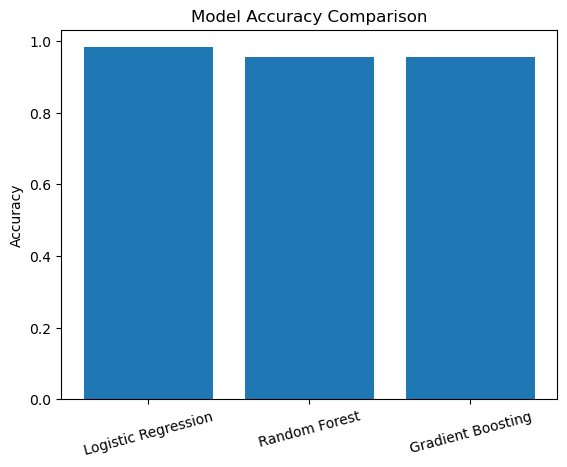

In [17]:
plt.bar(df["Model"], df["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.show()